In [19]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import QuantileTransformer, SplineTransformer

In [20]:
def show_weights(features, weights, scales):
    _, axs = plt.subplots(figsize=(14, 10), ncols=2)
    sorted_weights = sorted(zip(weights, features, scales), reverse=True)
    weights = [item[0] for item in sorted_weights]
    features = [item[1] for item in sorted_weights]
    scales = [item[2] for item in sorted_weights]
    sns.barplot(y=features, x=weights, ax=axs[0])
    axs[0].set_xlabel('Weight')
    sns.barplot(y=features, x=scales, ax=axs[1])
    axs[1].set_xlabel('Scale')
    plt.tight_layout()
    plt.show()

# Подготовка единого датасета

In [21]:
data_path = Path('data')
df_red = pd.read_csv(data_path / 'winequality-red.csv', sep=';').drop_duplicates()
df_white = pd.read_csv(data_path / 'winequality-white.csv', sep=';').drop_duplicates()
df_red['color'] = 0
df_white['color'] = 1
df_wine = pd.concat([df_red, df_white], ignore_index=True)
df_wine.shape

(5320, 13)

In [22]:
df_wine.isna().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
color                   0
dtype: int64

In [23]:
train_val, test = train_test_split(df_wine, test_size=0.15, random_state=3)
train, val = train_test_split(train_val, test_size=0.15 / 0.85, random_state=3)
X_train = train.drop(columns='quality')
y_train = train['quality']
X_val = val.drop(columns='quality')
y_val = val['quality']
X_test = test.drop(columns='quality')
y_test = test['quality']
print('train:', train.shape, 'validation:', val.shape, 'test:', test.shape)

train: (3724, 13) validation: (798, 13) test: (798, 13)


# Baseline

In [24]:
dummy = DummyRegressor(strategy='mean')
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
dummy_mse = mean_squared_error(y_test, dummy_pred)
baseline_metrics = pd.Series({
    'MSE': dummy_mse,
    'RMSE': dummy_mse ** 0.5,
}, name='DummyRegressor')
baseline_metrics

MSE     0.708461
RMSE    0.841701
Name: DummyRegressor, dtype: float64

# Анализ признаков до масштабирования

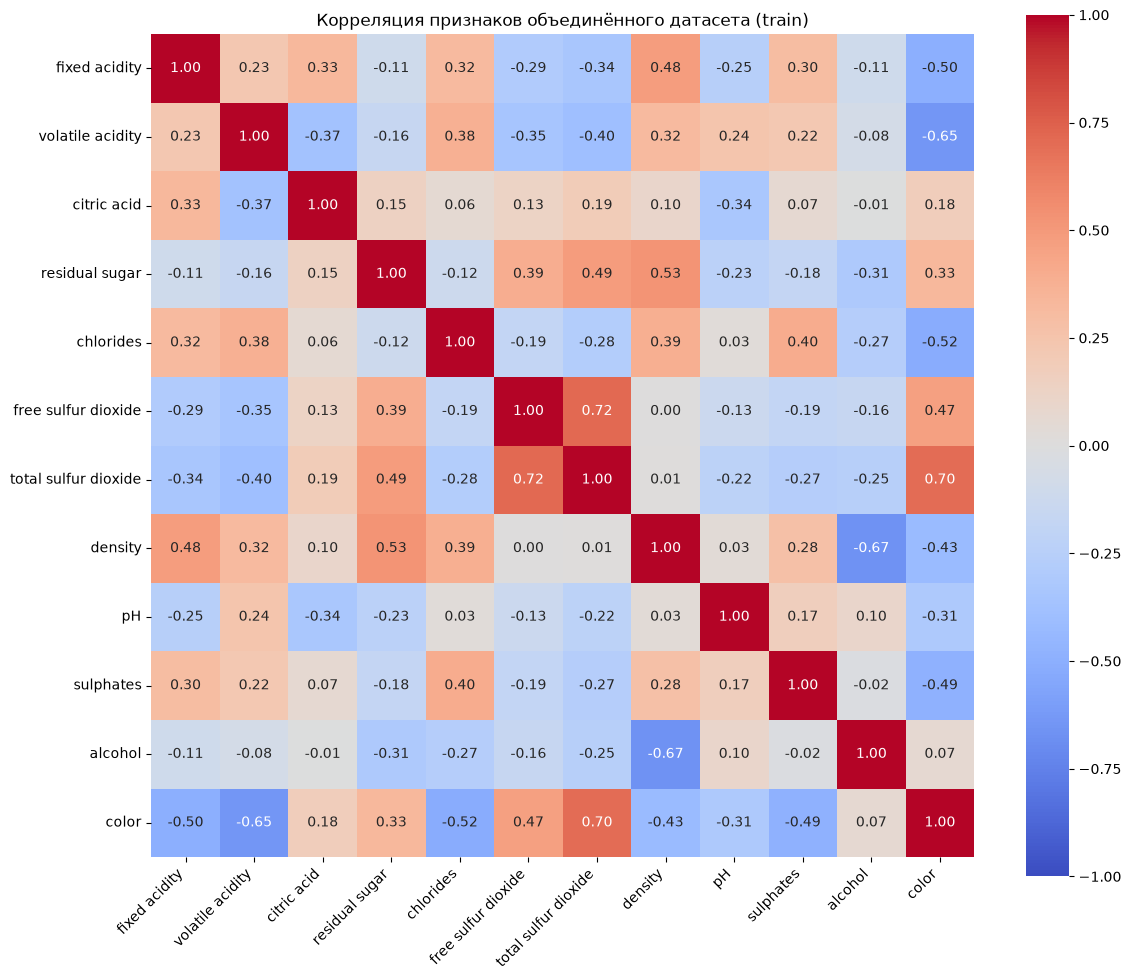

In [25]:
plt.figure(figsize=(12, 10))
sns.heatmap(X_train.corr(), annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, square=True)
plt.title('Корреляция признаков объединённого датасета (train)')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

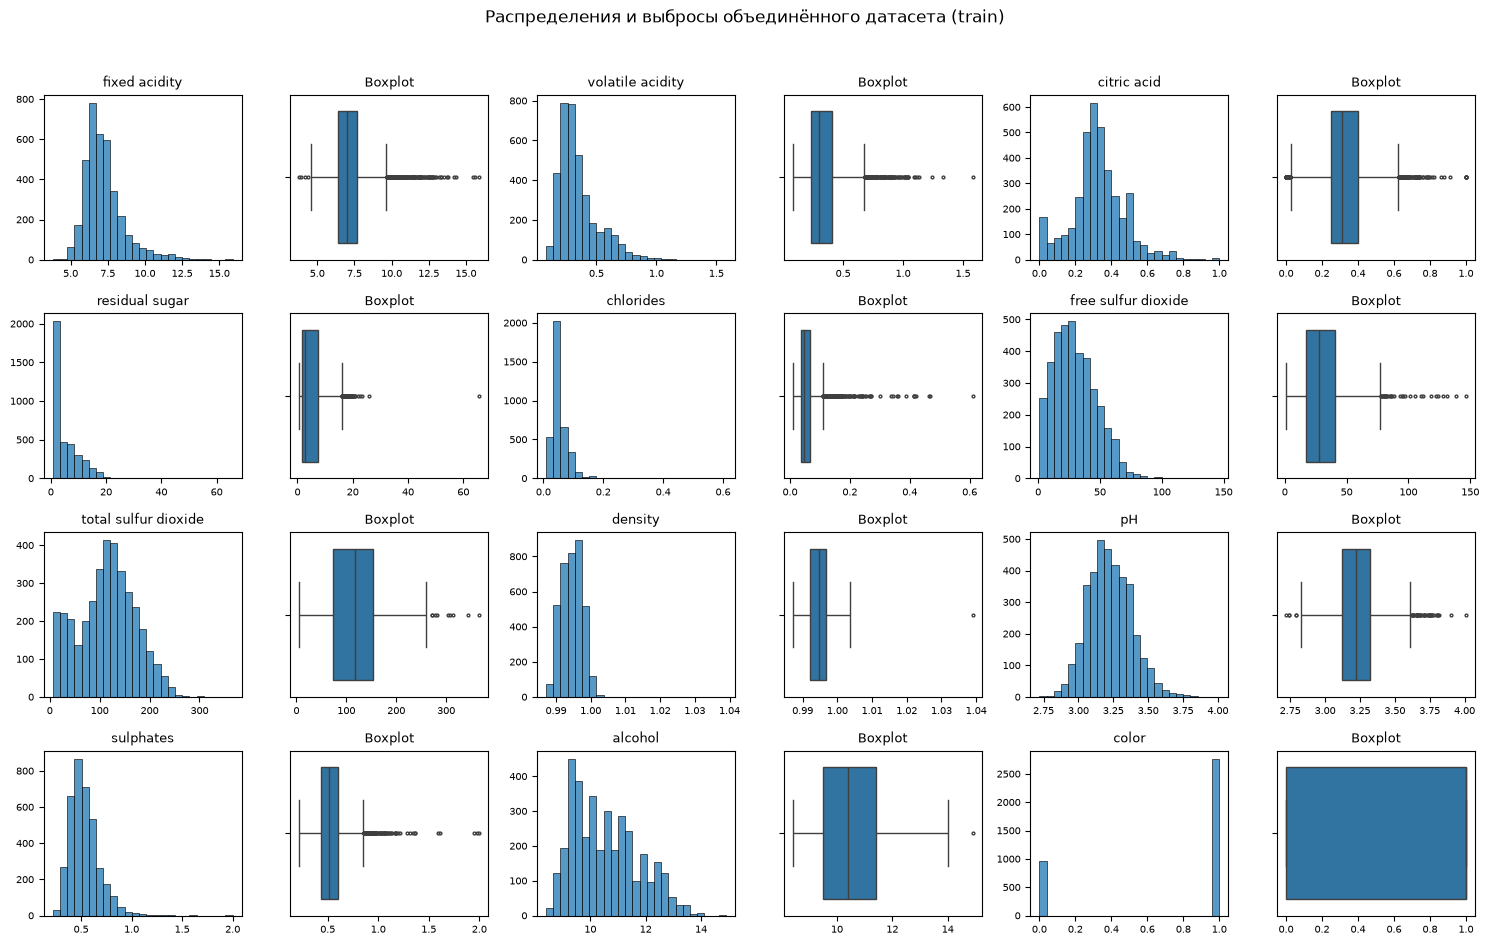

In [26]:
numeric_train = X_train.select_dtypes(include='number')
nrows = (numeric_train.shape[1] + 2) // 3
fig, axes = plt.subplots(nrows, 6, figsize=(15, 2.4 * nrows), squeeze=False)
for i, column in enumerate(numeric_train.columns):
    row, pair = divmod(i, 3)
    hist_ax, box_ax = axes[row, 2 * pair:2 * pair + 2]
    sns.histplot(numeric_train[column], bins=25, ax=hist_ax)
    sns.boxplot(x=numeric_train[column], whis=1.5, fliersize=2, ax=box_ax)
    hist_ax.set_title(column, fontsize=9)
    box_ax.set_title('Boxplot', fontsize=9)
    for ax in (hist_ax, box_ax):
        ax.set_xlabel('')
        ax.set_ylabel('')
        ax.tick_params(labelsize=7)
for i in range(numeric_train.shape[1], nrows * 3):
    row, pair = divmod(i, 3)
    axes[row, 2 * pair].set_visible(False)
    axes[row, 2 * pair + 1].set_visible(False)
fig.suptitle('Распределения и выбросы объединённого датасета (train)', fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

# Преобразование распределений

In [27]:
X_train_before_transform = X_train.copy()
X_val_before_transform = X_val.copy()
X_test_before_transform = X_test.copy()

transform_features = X_train.columns.difference(['color'])
quantile_transformer = QuantileTransformer(
    n_quantiles=min(1000, len(X_train)),
    output_distribution='normal',
    random_state=3,
)
X_train[transform_features] = quantile_transformer.fit_transform(X_train[transform_features])
X_val[transform_features] = quantile_transformer.transform(X_val[transform_features])
X_test[transform_features] = quantile_transformer.transform(X_test[transform_features])

skewness_comparison = pd.DataFrame({
    'before': X_train_before_transform[transform_features].skew(),
    'after': X_train[transform_features].skew(),
})
skewness_comparison

,before,after
alcohol,0.528749,-0.051462
chlorides,5.117703,0.000362
citric acid,0.329642,-1.425005
density,0.848120,-0.004125
fixed acidity,1.648553,0.004762
free sulfur dioxide,0.893472,-0.014020
pH,0.356881,-0.002770
residual sugar,1.814954,-0.101602
sulphates,1.876276,0.009724
total sulfur dioxide,0.042695,-0.024623


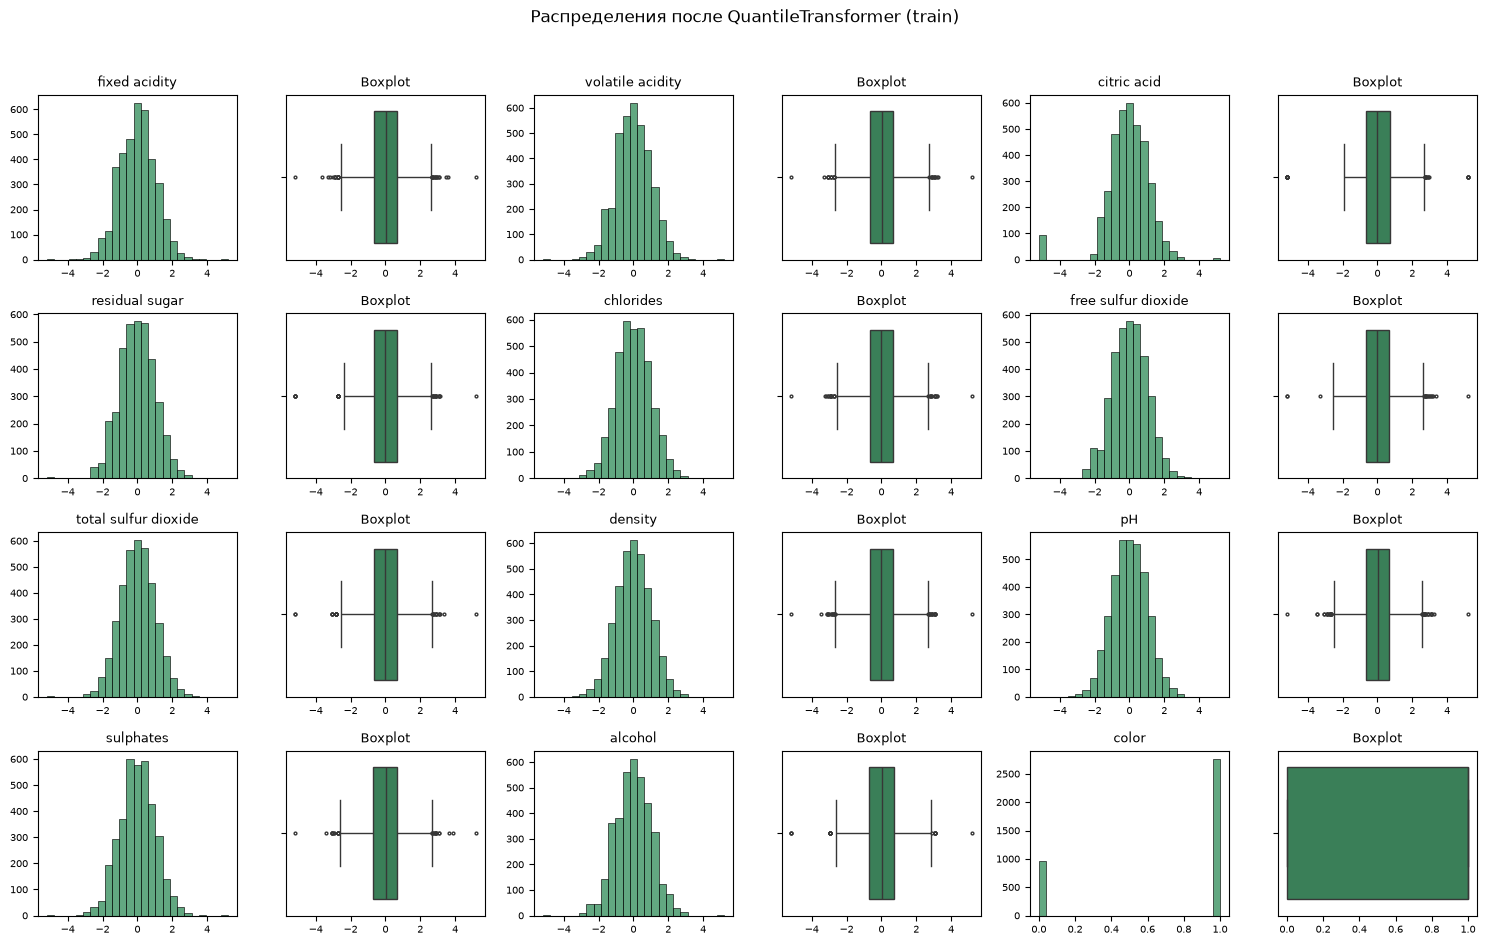

In [ ]:
numeric_train_quantile = X_train.select_dtypes(include='number')
nrows = (numeric_train_quantile.shape[1] + 2) // 3
fig, axes = plt.subplots(nrows, 6, figsize=(15, 2.4 * nrows), squeeze=False)
for i, column in enumerate(numeric_train_quantile.columns):
    row, pair = divmod(i, 3)
    hist_ax, box_ax = axes[row, 2 * pair:2 * pair + 2]
    sns.histplot(numeric_train_quantile[column], bins=25, color='seagreen', ax=hist_ax)
    sns.boxplot(x=numeric_train_quantile[column], color='seagreen', whis=1.5, fliersize=2, ax=box_ax)
    hist_ax.set_title(column, fontsize=9)
    box_ax.set_title('Boxplot', fontsize=9)
    for ax in (hist_ax, box_ax):
        ax.set_xlabel('')
        ax.set_ylabel('')
        ax.tick_params(labelsize=7)
for i in range(numeric_train_quantile.shape[1], nrows * 3):
    row, pair = divmod(i, 3)
    axes[row, 2 * pair].set_visible(False)
    axes[row, 2 * pair + 1].set_visible(False)
fig.suptitle('Распределения после QuantileTransformer (train)', fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

# Сплайновое преобразование признаков

In [29]:
spline_features = X_train.columns.difference(['color'])
spline_transformer = SplineTransformer(
    n_knots=5,
    degree=3,
    include_bias=False,
)

X_train_spline_values = spline_transformer.fit_transform(X_train[spline_features])
X_val_spline_values = spline_transformer.transform(X_val[spline_features])
X_test_spline_values = spline_transformer.transform(X_test[spline_features])

spline_feature_names = spline_transformer.get_feature_names_out(spline_features)
X_train_spline = pd.DataFrame(X_train_spline_values, columns=spline_feature_names, index=X_train.index)
X_val_spline = pd.DataFrame(X_val_spline_values, columns=spline_feature_names, index=X_val.index)
X_test_spline = pd.DataFrame(X_test_spline_values, columns=spline_feature_names, index=X_test.index)

X_train_spline['color'] = X_train['color']
X_val_spline['color'] = X_val['color']
X_test_spline['color'] = X_test['color']

X_train = X_train_spline
X_val = X_val_spline
X_test = X_test_spline

print('Количество признаков до SplineTransformer:', len(spline_features) + 1)
print('Количество признаков после SplineTransformer:', X_train.shape[1])

Количество признаков до SplineTransformer: 12
Количество признаков после SplineTransformer: 67


# Линейные модели

In [30]:
X_train_full = pd.concat([X_train, X_val])
y_train_full = pd.concat([y_train, y_val])
lower_bounds = X_train_full.quantile(0.05)
upper_bounds = X_train_full.quantile(0.95)
X_train_full_clean = X_train_full.clip(lower=lower_bounds, upper=upper_bounds, axis=1)
X_test_clean = X_test.clip(lower=lower_bounds, upper=upper_bounds, axis=1)
X_train_full_scaled = X_train_full_clean.copy()
X_test_scaled = X_test_clean.copy()

In [31]:
linear = LinearRegression()
linear.fit(X_train_full_scaled, y_train_full)
linear_pred = linear.predict(X_test_scaled)
linear_mse = mean_squared_error(y_test, linear_pred)
linear_metrics = pd.Series({
    'MSE': linear_mse,
    'RMSE': linear_mse ** 0.5,
}, name='LinearRegression')
linear_metrics

MSE     0.476119
RMSE    0.690014
Name: LinearRegression, dtype: float64

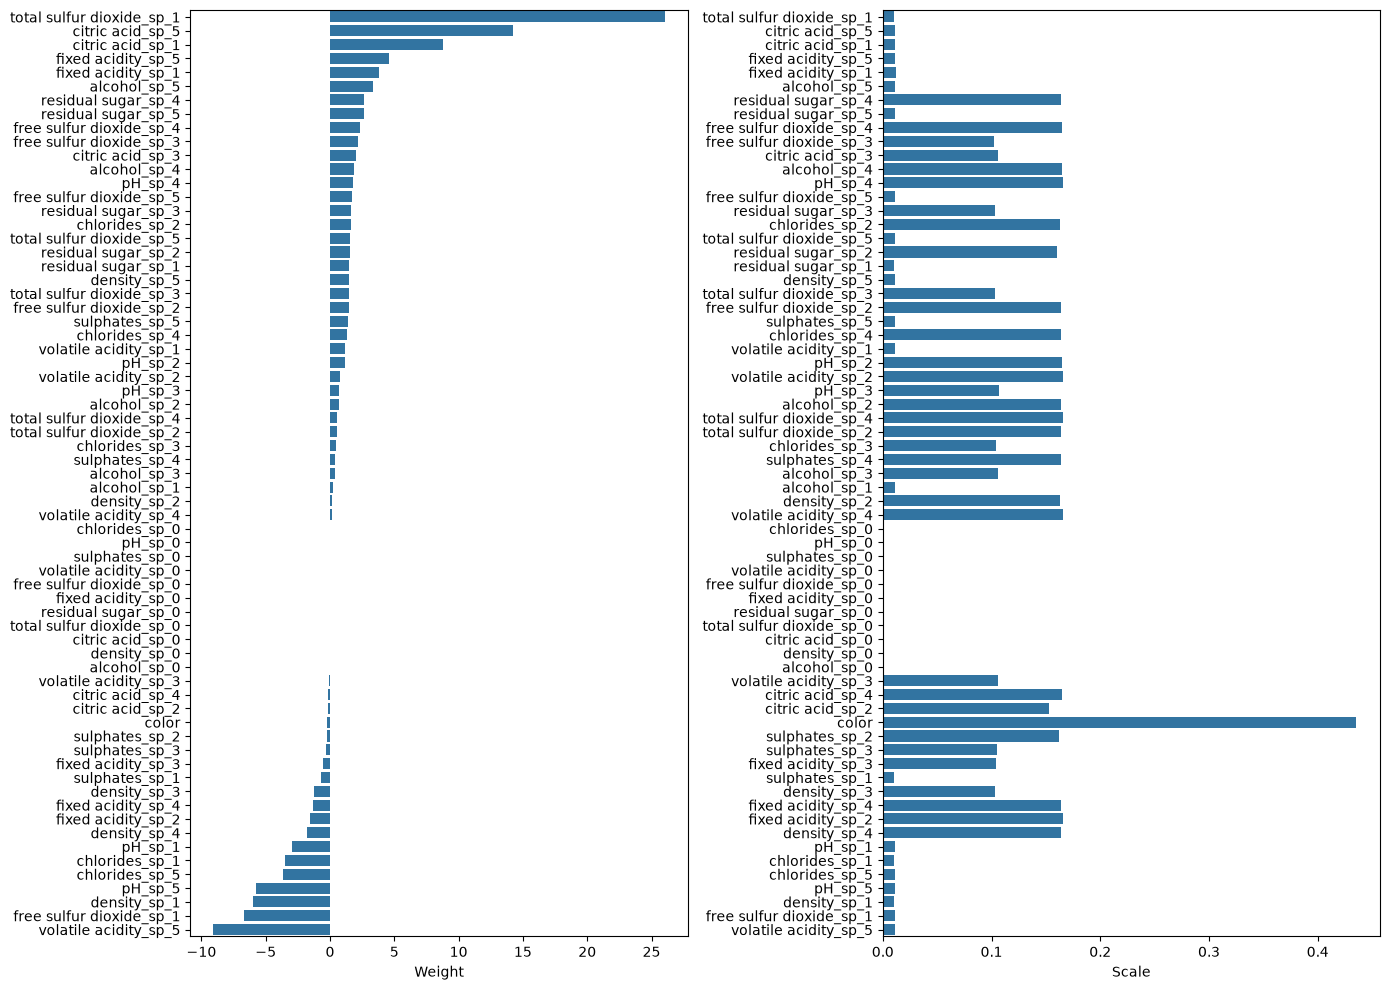

In [32]:
show_weights(
    X_train_full_scaled.columns,
    linear.coef_,
    X_train_full_scaled.std(ddof=1),
)

In [33]:
alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
ridge_grid = GridSearchCV(
    Ridge(),
    param_grid={'alpha': alphas},
    scoring='neg_mean_squared_error', cv=5, n_jobs=-1,
)
lasso_grid = GridSearchCV(
    Lasso(max_iter=100000),
    param_grid={'alpha': alphas},
    scoring='neg_mean_squared_error', cv=5, n_jobs=-1,
)
ridge_grid.fit(X_train_full_clean, y_train_full)
lasso_grid.fit(X_train_full_clean, y_train_full)
ridge_pred = ridge_grid.best_estimator_.predict(X_test_clean)
lasso_pred = lasso_grid.best_estimator_.predict(X_test_clean)
ridge_mse = mean_squared_error(y_test, ridge_pred)
lasso_mse = mean_squared_error(y_test, lasso_pred)
regularized_metrics = pd.DataFrame({
    'alpha': [ridge_grid.best_params_['alpha'], lasso_grid.best_params_['alpha']],
    'MSE': [ridge_mse, lasso_mse],
    'RMSE': [ridge_mse ** 0.5, lasso_mse ** 0.5],
}, index=['Ridge', 'Lasso'])
regularized_metrics

,alpha,MSE,RMSE
Ridge,0.0100,0.476063,0.689973
Lasso,0.0001,0.478537,0.691764


# Ансамблевые модели

In [34]:
rf_params = [
    {'n_estimators': 400, 'max_depth': depth, 'min_samples_leaf': leaf, 'max_features': features}
    for depth in [None, 10, 20] for leaf in [1, 2, 4] for features in ['sqrt', 1.0]
]
gb_params = [
    {'n_estimators': estimators, 'learning_rate': rate, 'max_depth': depth}
    for estimators in [100, 200] for rate in [0.03, 0.05, 0.1] for depth in [2, 3]
]
rf_val_results = []
for params in rf_params:
    model = RandomForestRegressor(**params, random_state=3, n_jobs=-1)
    model.fit(X_train, y_train)
    rf_val_results.append((mean_squared_error(y_val, model.predict(X_val)), params))
gb_val_results = []
for params in gb_params:
    model = GradientBoostingRegressor(**params, random_state=3)
    model.fit(X_train, y_train)
    gb_val_results.append((mean_squared_error(y_val, model.predict(X_val)), params))
best_rf_params = min(rf_val_results, key=lambda item: item[0])[1]
best_gb_params = min(gb_val_results, key=lambda item: item[0])[1]
best_rf_params, best_gb_params

({'n_estimators': 400,
  'max_depth': 20,
  'min_samples_leaf': 1,
  'max_features': 'sqrt'},
 {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 3})

In [35]:
random_forest = RandomForestRegressor(**best_rf_params, random_state=3, n_jobs=-1)
gradient_boosting = GradientBoostingRegressor(**best_gb_params, random_state=3)
random_forest.fit(X_train_full, y_train_full)
gradient_boosting.fit(X_train_full, y_train_full)
rf_pred = random_forest.predict(X_test)
gb_pred = gradient_boosting.predict(X_test)
rf_mse = mean_squared_error(y_test, rf_pred)
gb_mse = mean_squared_error(y_test, gb_pred)
ensemble_metrics = pd.DataFrame({
    'MSE': [rf_mse, gb_mse],
    'RMSE': [rf_mse ** 0.5, gb_mse ** 0.5],
}, index=['RandomForest', 'GradientBoosting'])
ensemble_metrics

,MSE,RMSE
RandomForest,0.442606,0.665287
GradientBoosting,0.469392,0.685122


# Сравнение моделей

In [36]:
comparison_metrics = pd.concat([
    baseline_metrics.to_frame().T,
    linear_metrics.to_frame().T,
    regularized_metrics[['MSE', 'RMSE']],
    ensemble_metrics,
])
comparison_metrics.sort_values('RMSE')

,MSE,RMSE
RandomForest,0.442606,0.665287
GradientBoosting,0.469392,0.685122
Ridge,0.476063,0.689973
LinearRegression,0.476119,0.690014
Lasso,0.478537,0.691764
DummyRegressor,0.708461,0.841701


## Важность признаков для ансамблевых моделей

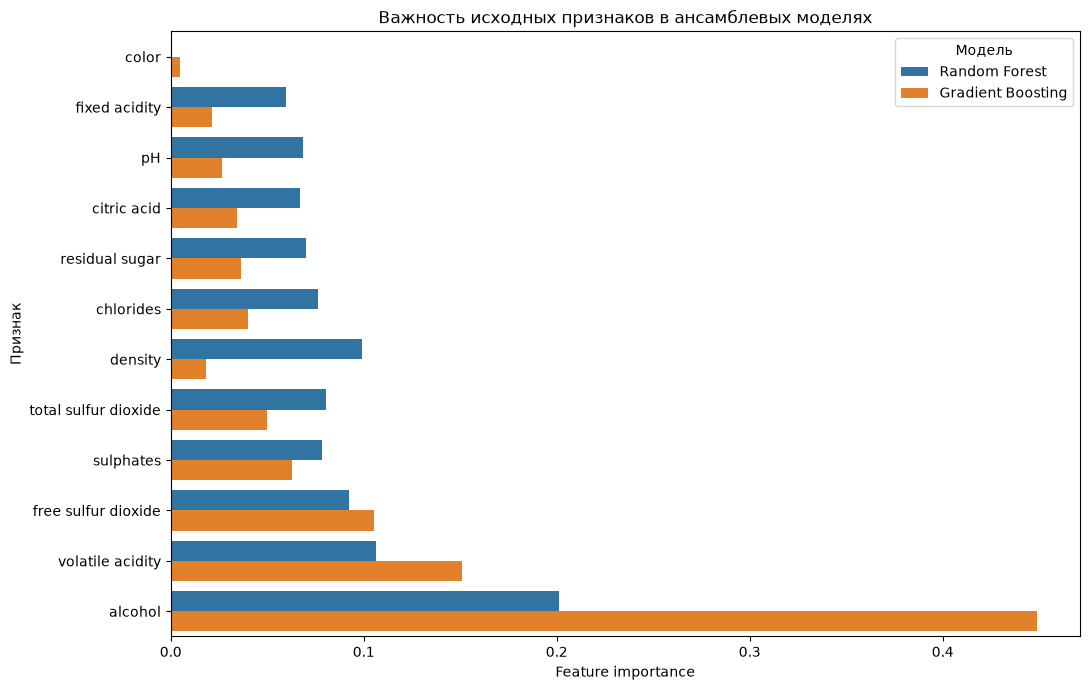

,Random Forest,Gradient Boosting
alcohol,0.2010,0.4487
volatile acidity,0.1066,0.1510
density,0.0990,0.0182
free sulfur dioxide,0.0923,0.1055
total sulfur dioxide,0.0802,0.0498
sulphates,0.0786,0.0630
chlorides,0.0763,0.0401
residual sugar,0.0699,0.0364
pH,0.0683,0.0267
citric acid,0.0669,0.0342


In [37]:
def aggregate_spline_importance(model, transformed_columns, original_features):
    importance = pd.Series(model.feature_importances_, index=transformed_columns)
    aggregated = {}
    for feature in original_features:
        spline_columns = importance.index.str.startswith(f'{feature}_sp_')
        aggregated[feature] = importance.loc[spline_columns].sum()
    aggregated['color'] = importance.get('color', 0.0)
    return pd.Series(aggregated)

feature_importance = pd.DataFrame({
    'Random Forest': aggregate_spline_importance(
        random_forest, X_train_full.columns, spline_features
    ),
    'Gradient Boosting': aggregate_spline_importance(
        gradient_boosting, X_train_full.columns, spline_features
    ),
})
feature_importance['mean_importance'] = feature_importance.mean(axis=1)
feature_importance = feature_importance.sort_values('mean_importance', ascending=True)

importance_long = (
    feature_importance.drop(columns='mean_importance')
    .rename_axis('feature')
    .reset_index()
    .melt(id_vars='feature', var_name='model', value_name='importance')
)

plt.figure(figsize=(11, 7))
sns.barplot(data=importance_long, y='feature', x='importance', hue='model')
plt.title('Важность исходных признаков в ансамблевых моделях')
plt.xlabel('Feature importance')
plt.ylabel('Признак')
plt.legend(title='Модель')
plt.tight_layout()
plt.show()

feature_importance.drop(columns='mean_importance').sort_values(
    'Random Forest', ascending=False
).round(4)